# Comparação centralizada — deteção binária de anomalias

Todos os 14 modelos por dataset são treinados com duas classes: **N = normal (0); A/O ou S/V = anomalia (1)**. ~ e Q são excluídos antes do treino, avaliação e normalização. O conjunto test não é carregado.

Mesmos IDs shared_smoke_v2, filtrados no protocolo `binary_smoke_v3`. PhysioNet: **354 fit / 59 dev**. Icentia: **792 fit / 94 dev**. Holdouts locais FL separados (90 e 203). O ranking usa **PR-AUC da anomalia**, com ROC-AUC positivo como desempate. As métricas principais F1, precision, recall, miss rate e FAR referem-se à classe anomalia; métricas macro são auxiliares.

São smoke tests com sinal + features. Todas as arquiteturas, projeções e orçamentos estão descritos nos notebooks individuais; SVM central é RBF e FL linear. As tarefas de origem, prevalências e amostras pequenas limitam a comparação entre datasets.

In [1]:
from pathlib import Path
import json
import nbformat
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
PROJECT_ROOT=Path.cwd().resolve()
while not (PROJECT_ROOT/'requirements.txt').is_file() and PROJECT_ROOT!=PROJECT_ROOT.parent:PROJECT_ROOT=PROJECT_ROOT.parent
ARTIFACTS=PROJECT_ROOT/'artifacts/test_models/comparison_plots';ARTIFACTS.mkdir(parents=True,exist_ok=True)
DATASET_NAMES={'physionet2017':'PhysioNet 2017','icentia11k':'Icentia11k'}
PR='anomaly_pr_auc_ap'


In [2]:
def read_results(path,dataset):
    n=nbformat.read(path,4)
    payloads=[o['data']['application/json'] for c in n.cells for o in c.get('outputs',[]) if isinstance(o.get('data',{}).get('application/json'),dict) and o['data']['application/json'].get('kind')=='ecg_validation_results']
    p=payloads[-1]
    assert p['dataset']==dataset and p['protocol']['id']=='binary_smoke_v3' and p['protocol']['task']=='binary' and p['protocol']['test_used'] is False
    assert len(p['rows'])==14
    return p
payloads={ds:read_results(PROJECT_ROOT/'Tests'/('test_models_physionet.ipynb' if ds=='physionet2017' else 'test_models_icentia11k.ipynb'),ds) for ds in DATASET_NAMES}
results=pd.concat([pd.DataFrame(p['rows']).assign(dataset=ds) for ds,p in payloads.items()],ignore_index=True)
assert results.groupby('dataset').model.nunique().eq(14).all()


## Gráficos — PR-AUC da classe anomalia em dev

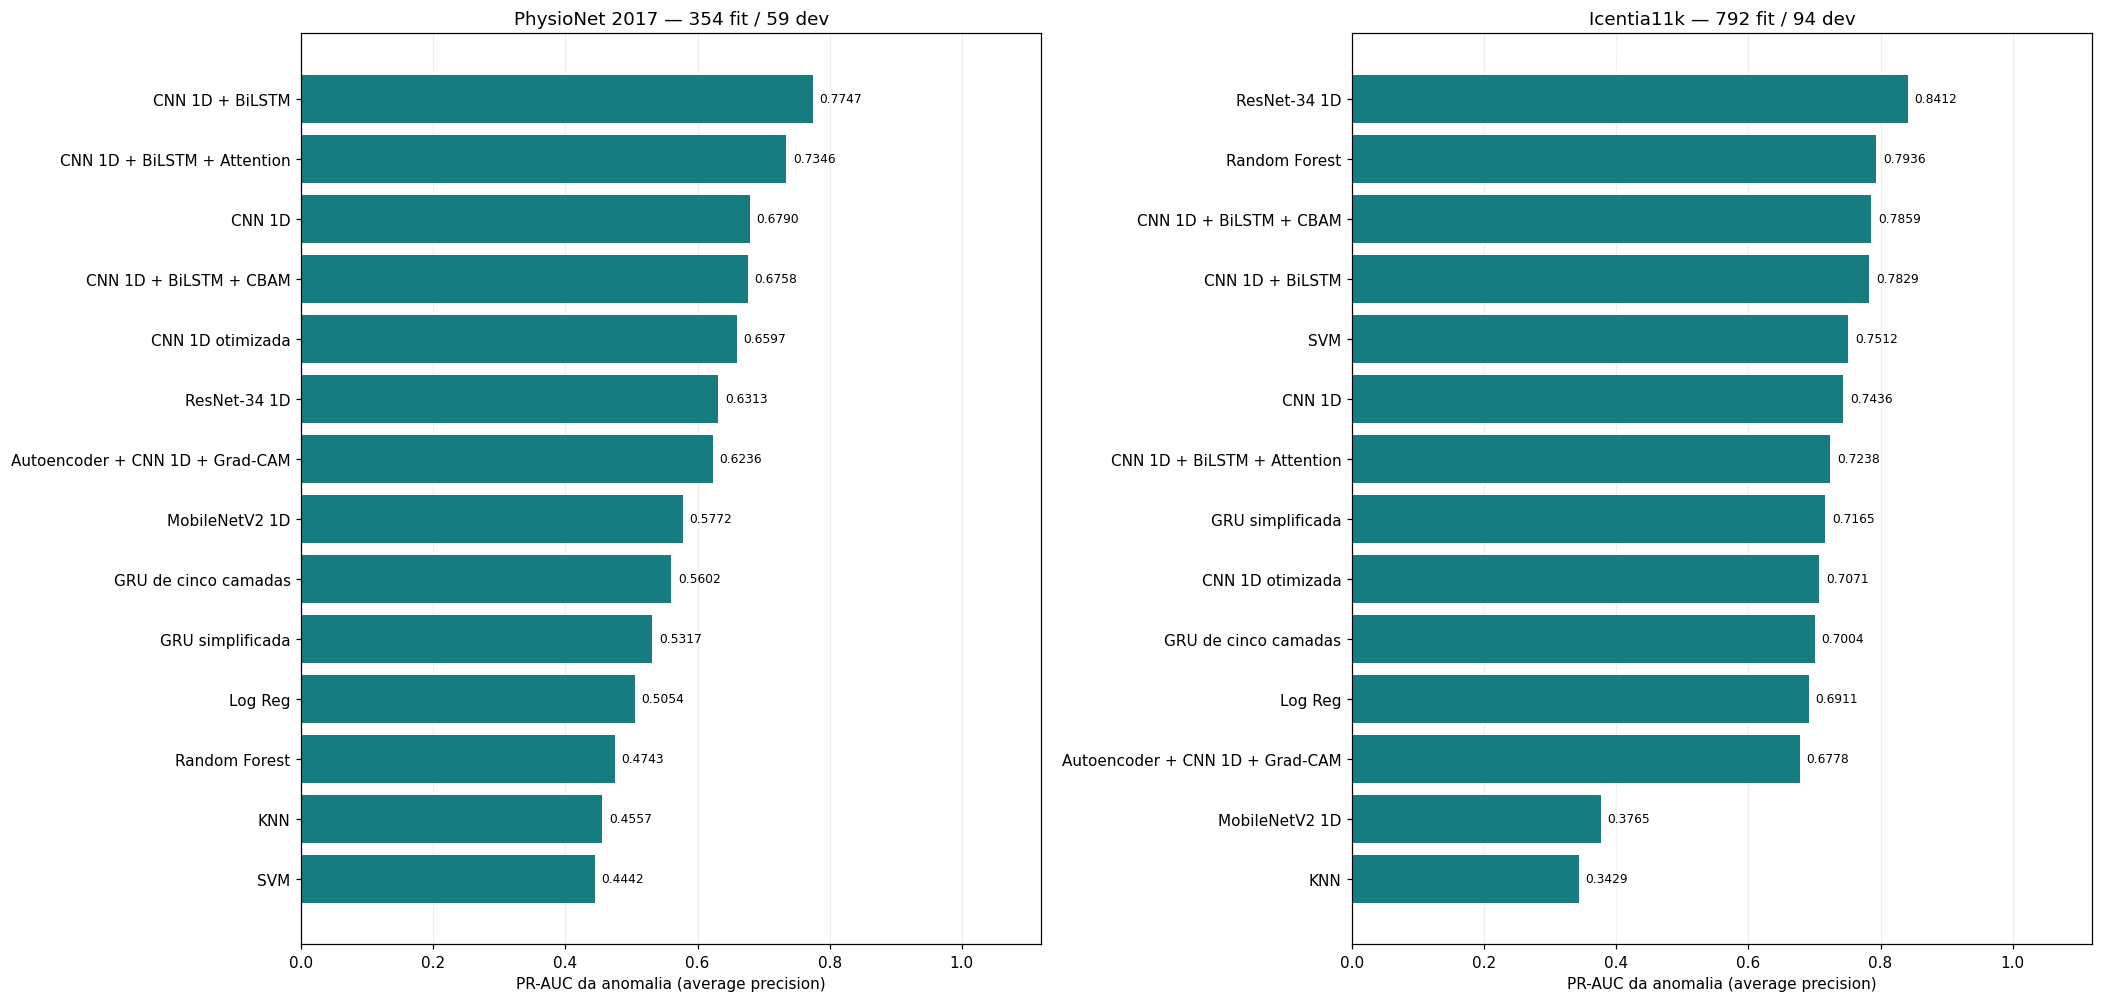

In [3]:
fig,axes=plt.subplots(1,2,figsize=(19,9),constrained_layout=True)
for ax,(ds,title) in zip(axes,DATASET_NAMES.items()):
    part=results[results.dataset==ds].sort_values([PR,'anomaly_roc_auc'],ascending=False)
    bars=ax.barh(part.model,part[PR],color='#167c80')
    for bar,value in zip(bars,part[PR]):ax.text(value+.01,bar.get_y()+bar.get_height()/2,f'{value:.4f}',va='center',fontsize=8)
    ax.invert_yaxis();ax.set_xlim(0,1.12);ax.set_xlabel('PR-AUC da anomalia (average precision)')
    protocol=payloads[ds]['protocol'];ax.set_title(f"{title} — {protocol['train_examples']} fit / {protocol['dev_examples']} dev")
    ax.grid(axis='x',alpha=.2);ax.set_axisbelow(True)
fig.savefig(ARTIFACTS/'centralized_pr_auc.png',dpi=160,bbox_inches='tight');plt.show();plt.close(fig)


## Métricas binárias e miss rate

In [4]:
for ds,title in DATASET_NAMES.items():
    part=results[results.dataset==ds].sort_values([PR,'anomaly_roc_auc'],ascending=False)
    assert np.allclose(part.miss_rate,1-part.recall,equal_nan=True)
    print(title)
    display(part[['model','accuracy','f1','precision','recall','roc_auc',PR,'miss_rate','far']].round(4).reset_index(drop=True))
    display(part[['model','recall','miss_rate','far',PR]].rename(columns={'model':'Modelo','recall':'Recall da anomalia','miss_rate':'Miss rate ↓','far':'FAR ↓',PR:'PR-AUC da anomalia'}).round(4).reset_index(drop=True))
    best=part.iloc[0];print(f"Candidato exploratório: {best['model']}; AP positivo = {best[PR]:.4f}.")


,model,accuracy,f1,precision,recall,roc_auc,anomaly_pr_auc_ap,miss_rate,far
0,CNN 1D + BiLSTM,0.7288,0.6000,0.8000,0.48,0.8176,0.7747,0.52,0.0882
1,CNN 1D + BiLSTM + Attention,0.6610,0.4737,0.6923,0.36,0.7729,0.7346,0.64,0.1176
2,CNN 1D,0.7119,0.6383,0.6818,0.60,0.7612,0.6790,0.40,0.2059
3,CNN 1D + BiLSTM + CBAM,0.6441,0.6038,0.5714,0.64,0.7318,0.6758,0.36,0.3529
4,CNN 1D otimizada,0.6271,0.3889,0.6364,0.28,0.7153,0.6597,0.72,0.1176
5,ResNet-34 1D,0.5763,0.0741,0.5000,0.04,0.6882,0.6313,0.96,0.0294
6,Autoencoder + CNN 1D + Grad-CAM,0.6780,0.6275,0.6154,0.64,0.7118,0.6236,0.36,0.2941
7,MobileNetV2 1D,0.6102,0.4390,0.5625,0.36,0.5529,0.5772,0.64,0.2059
8,GRU de cinco camadas,0.4746,0.5634,0.4348,0.80,0.6447,0.5602,0.20,0.7647
9,GRU simplificada,0.5254,0.5333,0.4571,0.64,0.5694,0.5317,0.36,0.5588


,Modelo,Recall da anomalia,Miss rate ↓,FAR ↓,PR-AUC da anomalia
0,CNN 1D + BiLSTM,0.48,0.52,0.0882,0.7747
1,CNN 1D + BiLSTM + Attention,0.36,0.64,0.1176,0.7346
2,CNN 1D,0.60,0.40,0.2059,0.6790
3,CNN 1D + BiLSTM + CBAM,0.64,0.36,0.3529,0.6758
4,CNN 1D otimizada,0.28,0.72,0.1176,0.6597
5,ResNet-34 1D,0.04,0.96,0.0294,0.6313
6,Autoencoder + CNN 1D + Grad-CAM,0.64,0.36,0.2941,0.6236
7,MobileNetV2 1D,0.36,0.64,0.2059,0.5772
8,GRU de cinco camadas,0.80,0.20,0.7647,0.5602
9,GRU simplificada,0.64,0.36,0.5588,0.5317


,model,accuracy,f1,precision,recall,roc_auc,anomaly_pr_auc_ap,miss_rate,far
0,ResNet-34 1D,0.9149,0.6667,0.8889,0.5333,0.9502,0.8412,0.4667,0.0127
1,Random Forest,0.8723,0.3333,1.0000,0.2000,0.8722,0.7936,0.8000,0.0000
2,CNN 1D + BiLSTM + CBAM,0.8723,0.6471,0.5789,0.7333,0.8793,0.7859,0.2667,0.1013
3,CNN 1D + BiLSTM,0.9149,0.6667,0.8889,0.5333,0.8928,0.7829,0.4667,0.0127
4,SVM,0.9043,0.6087,0.8750,0.4667,0.8515,0.7512,0.5333,0.0127
5,CNN 1D,0.8830,0.6207,0.6429,0.6000,0.8658,0.7436,0.4000,0.0633
6,CNN 1D + BiLSTM + Attention,0.7979,0.5581,0.4286,0.8000,0.9055,0.7238,0.2000,0.2025
7,GRU simplificada,0.8830,0.6452,0.6250,0.6667,0.9241,0.7165,0.3333,0.0759
8,CNN 1D otimizada,0.9149,0.6667,0.8889,0.5333,0.8253,0.7071,0.4667,0.0127
9,GRU de cinco camadas,0.9043,0.6400,0.8000,0.5333,0.8692,0.7004,0.4667,0.0253


,Modelo,Recall da anomalia,Miss rate ↓,FAR ↓,PR-AUC da anomalia
0,ResNet-34 1D,0.5333,0.4667,0.0127,0.8412
1,Random Forest,0.2000,0.8000,0.0000,0.7936
2,CNN 1D + BiLSTM + CBAM,0.7333,0.2667,0.1013,0.7859
3,CNN 1D + BiLSTM,0.5333,0.4667,0.0127,0.7829
4,SVM,0.4667,0.5333,0.0127,0.7512
5,CNN 1D,0.6000,0.4000,0.0633,0.7436
6,CNN 1D + BiLSTM + Attention,0.8000,0.2000,0.2025,0.7238
7,GRU simplificada,0.6667,0.3333,0.0759,0.7165
8,CNN 1D otimizada,0.5333,0.4667,0.0127,0.7071
9,GRU de cinco camadas,0.5333,0.4667,0.0253,0.7004


PhysioNet 2017
Candidato exploratório: CNN 1D + BiLSTM; AP positivo = 0.7747.
Icentia11k
Candidato exploratório: ResNet-34 1D; AP positivo = 0.8412.


## Percentagens efetivamente utilizadas de train e dev

Denominador: split preparado original, antes de excluir ~ / Q. O treino efetivo é comum ao centralizado e FL. O holdout local não participa no ajuste dos modelos. Todos os clientes de treino/dev se mantêm representados; a filtragem não muda os IDs entre splits.

In [5]:
sampling=pd.DataFrame([r for p in payloads.values() for r in p['sampling']])
usage=sampling[['dataset','split','clients','available','fit_or_dev','used_percent','excluded_selected']].rename(columns={'dataset':'Dataset','split':'Split','clients':'Clientes','available':'Total original do split','fit_or_dev':'Exemplos utilizados','used_percent':'Percentagem (%)','excluded_selected':'Excluídos ~ / Q da seleção'})
display(usage.round(6))
display(sampling[sampling.split=='train'][['dataset','local_holdout','selected','selected_percent']].round(6))
print('Test: zero exemplos utilizados. Os PNGs de matrizes de confusão em dev estão nos notebooks individuais.')


,Dataset,Split,Clientes,Total original do split,Exemplos utilizados,Percentagem (%),Excluídos ~ / Q da seleção
0,physionet2017,train,6,6398,354,5.532979,36
1,physionet2017,dev,1,1065,59,5.539906,5
2,icentia11k,train,16,3904222,792,0.020286,285
3,icentia11k,dev,2,470000,94,0.020000,34


,dataset,local_holdout,selected,selected_percent
0,physionet2017,90,444,6.939669
2,icentia11k,203,995,0.025485


Test: zero exemplos utilizados. Os PNGs de matrizes de confusão em dev estão nos notebooks individuais.
